# Sesión 3 · Del dato al conocimiento
## Laboratorio 1: extracción y automatización con Python
**Sistemas de Big Data · CEU · Duración orientativa: 55 minutos**

Construiremos un proceso ETL que lee 12 CSV, comprueba su estructura, transforma sus datos, separa errores y publica informes. Trabajaremos con **600.000 registros sintéticos** (50.000 por mes), más 1.200 duplicados añadidos deliberadamente. No representan ventas reales. Es un volumen significativo para una primera práctica local, no un sistema distribuido de Big Data.

**Pregunta de negocio:** ¿cuál es el importe de ventas completadas por mes y canal y qué porcentaje de registros no puede utilizarse?

Prerrequisitos: variables, funciones, listas y bucles básicos. No se necesita GPU ni descargar datos. La primera instalación de paquetes sí requiere Internet. El volumen se puede reducir con `FILAS_POR_MES`.


## 0 · Preparación
### Visual Studio Code
Instala Python 3.11 o posterior y las extensiones Python y Jupyter de Microsoft. Abre una carpeta de trabajo y ejecuta en una terminal PowerShell:
```powershell
py -m venv .venv
.\.venv\Scripts\python.exe -m pip install "pandas>=2.2,<4" "numpy>=1.26,<3" "matplotlib>=3.8,<4" ipykernel
```
En macOS/Linux utiliza `python3 -m venv .venv` y `.venv/bin/python -m pip install pandas numpy matplotlib ipykernel`.
Abre este cuaderno y elige **Seleccionar kernel → Entornos de Python → .venv**. No es necesario activar el entorno en PowerShell.

### Google Colab
Abre https://colab.research.google.com/ y selecciona **Archivo → Subir cuaderno**. Usa un entorno de CPU. Si falta alguna dependencia, ejecuta la celda opcional siguiente. Después ejecuta las celdas en orden. Los archivos del entorno de Colab son temporales: descarga el ZIP al finalizar.

La práctica escribe únicamente dentro de `laboratorio_s03`; una nueva ejecución reemplaza los archivos generados con los mismos nombres. No edites los datos generados si quieres conservar la reproducibilidad.


In [6]:
# Opcional: quita el # solo si faltan paquetes en el kernel seleccionado.
%pip install "pandas>=2.2,<4" "numpy>=1.26,<3" "matplotlib>=3.8,<4" ipykernel


  Using cached pandas-3.1.0-cp314-cp314-win_amd64.whl.metadata (18 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp314-cp314-win_amd64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached pandas-3.1.0-cp314-cp314-win_amd64.whl (10.9 MB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.67.0-cp314-cp314-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

   ---------------------------------------- 0/7 [pyparsing]
   ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
from pathlib import Path
from time import perf_counter
import calendar
import hashlib
import json
import platform
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEMILLA = 42
FILAS_POR_MES = 50_000  # Prueba 5_000 en un equipo con poca memoria.
assert FILAS_POR_MES >= 1_000
BASE = Path.cwd() / 'laboratorio_s03'
ENTRADA, SALIDA = BASE / 'entrada', BASE / 'salida'
for carpeta in (ENTRADA, SALIDA):
    carpeta.mkdir(parents=True, exist_ok=True)
print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| NumPy:', np.__version__)
print('Directorio:', BASE)


Python: 3.14.6 | pandas: 3.1.0 | NumPy: 2.5.1
Directorio: c:\Users\usuario\Desktop\CEU\Sistemas de big data\Entorno virtual\laboratorio_s03


## 1 · Crear una fuente reproducible
Cada fila representa **una operación de venta**, no una persona. `id` identifica la operación; `fecha` usa AAAA-MM-DD; `canal` es web o tienda; `estado` puede ser completado o cancelado; `unidades` es un entero positivo y `precio_centimos` es el precio unitario en céntimos de euro. El uso de enteros evita errores de redondeo monetario. `referencia` contiene un código que extraeremos con una expresión regular.

Por mes introducimos 100 fechas inválidas, 100 unidades negativas y 100 precios ausentes en filas distintas. Añadimos después 100 copias exactas. Normalizar espacios y mayúsculas no equivale a descartar datos.


In [ ]:
rng = np.random.default_rng(SEMILLA)
for mes in range(1, 13):
    n = FILAS_POR_MES
    dias = rng.integers(1, calendar.monthrange(2025, mes)[1] + 1, n)
    tabla = pd.DataFrame({
        'id': np.arange((mes - 1) * n + 1, mes * n + 1),
        'fecha': [f'2025-{mes:02d}-{d:02d}' for d in dias],
        'canal': rng.choice([' WEB ', 'web', 'Tienda', ' tienda '], n),
        'estado': rng.choice(['completado', 'cancelado'], n, p=[0.9, 0.1]),
        'unidades': rng.integers(1, 8, n),
        'precio_centimos': rng.integers(300, 20_001, n),
        'referencia': rng.choice(['SKU-101 | hogar', 'SKU-202 | ocio', 'SKU-303 | oficina'], n)
    })
    tabla['precio_centimos'] = tabla['precio_centimos'].astype('Int64')
    tabla.loc[0:99, 'fecha'] = 'fecha_desconocida'
    tabla.loc[100:199, 'unidades'] = -1
    tabla.loc[200:299, 'precio_centimos'] = pd.NA
    tabla = pd.concat([tabla, tabla.iloc[-100:]], ignore_index=True)
    tabla.to_csv(ENTRADA / f'ventas_2025_{mes:02d}.csv', index=False)
archivos = sorted(ENTRADA.glob('ventas_2025_??.csv'))
assert len(archivos) == 12
print(f'{len(archivos)} archivos; {sum(p.stat().st_size for p in archivos)/1e6:.1f} MB en disco')

12 archivos; 36.1 MB en disco
[ 4  3 10 ... 13  6 18]


## 2 · Extraer e inspeccionar antes de transformar
Extraer significa obtener los datos de la fuente. `read_csv` interpreta un archivo delimitado; `concat` integra las tablas. La columna `archivo_origen` conserva la trazabilidad. Una comprobación de esquema evita procesar silenciosamente archivos incompletos.


In [11]:
COLUMNAS = ['id', 'fecha', 'canal', 'estado', 'unidades', 'precio_centimos', 'referencia']
def extraer(carpeta):
    rutas = sorted(carpeta.glob('ventas_2025_??.csv'))
    if len(rutas) != 12:
        raise ValueError(f'Se esperaban 12 archivos y hay {len(rutas)}')
    tablas = []
    for ruta in rutas:
        datos = pd.read_csv(ruta, dtype='string')
        if list(datos.columns) != COLUMNAS:
            raise ValueError(f'Esquema incorrecto: {ruta.name}')
        datos['archivo_origen'] = ruta.name
        tablas.append(datos)
    return pd.concat(tablas, ignore_index=True)

brutos = extraer(ENTRADA)
display(brutos.head(3))
print('Dimensiones:', brutos.shape)
print(f'Memoria de la tabla: {brutos.memory_usage(deep=True).sum()/1e6:.1f} MB')
display(brutos.isna().sum().rename('ausentes'))


,id,fecha,canal,estado,unidades,precio_centimos,referencia,archivo_origen
0,1,fecha_desconocida,WEB,completado,7,14283,SKU-202 | ocio,ventas_2025_01.csv
1,2,fecha_desconocida,tienda,completado,7,8525,SKU-303 | oficina,ventas_2025_01.csv
2,3,fecha_desconocida,Tienda,completado,7,14310,SKU-303 | oficina,ventas_2025_01.csv


Dimensiones: (601200, 8)
Memoria de la tabla: 277.8 MB


id                    0
fecha                 0
canal                 0
estado                0
unidades              0
precio_centimos    1200
referencia            0
archivo_origen        0
Name: ausentes, dtype: int64

## 3 · Transformar y controlar la calidad
Política de esta práctica: eliminar duplicados exactos de negocio; detener el proceso si un mismo ID tiene datos distintos; rechazar campos esenciales inválidos sin imputar precios. `errors="coerce"` convierte errores a valores ausentes para poder identificarlos, **no los corrige**. El motivo de rechazo puede contener varias causas.


In [12]:
def transformar(brutos):
    datos = brutos.drop_duplicates(subset=COLUMNAS).copy()
    duplicados = len(brutos) - len(datos)
    if datos['id'].duplicated().any():
        raise ValueError('Hay IDs con datos distintos: investigar antes de continuar')
    datos['fecha'] = pd.to_datetime(datos['fecha'], format='%Y-%m-%d', errors='coerce')
    for columna in ['id', 'unidades', 'precio_centimos']:
        datos[columna] = pd.to_numeric(datos[columna], errors='coerce')
    for columna in ['canal', 'estado']:
        datos[columna] = datos[columna].str.strip().str.lower()
    datos['sku'] = datos['referencia'].str.extract(r'^(SKU-\d{3}) \|', expand=False)
    reglas = {
        'fecha_invalida': datos['fecha'].isna(),
        'id_invalido': datos['id'].isna() | (datos['id'] <= 0) | (datos['id'] % 1 != 0),
        'unidades_invalidas': datos['unidades'].isna() | (datos['unidades'] <= 0) | (datos['unidades'] % 1 != 0),
        'precio_invalido': datos['precio_centimos'].isna() | (datos['precio_centimos'] <= 0) | (datos['precio_centimos'] % 1 != 0),
        'canal_invalido': ~datos['canal'].isin(['web', 'tienda']),
        'estado_invalido': ~datos['estado'].isin(['completado', 'cancelado']),
        'sku_invalido': datos['sku'].isna()
    }
    motivo = pd.Series('', index=datos.index, dtype='string')
    for nombre, mascara in reglas.items():
        motivo.loc[mascara.fillna(True)] += nombre + ';'
    rechazados = datos.loc[motivo.ne('')].copy()
    rechazados['motivo'] = motivo.loc[rechazados.index].str.rstrip(';')
    validos = datos.loc[motivo.eq('')].copy()
    for columna in ['id', 'unidades', 'precio_centimos']:
        validos[columna] = validos[columna].astype('int64')
    validos['importe_centimos'] = validos['unidades'] * validos['precio_centimos']
    validos['mes'] = validos['fecha'].dt.strftime('%Y-%m')
    auditoria = {'leidos': len(brutos), 'duplicados': duplicados,
                 'rechazados': len(rechazados), 'validos': len(validos)}
    assert auditoria['leidos'] == sum(auditoria[k] for k in ['duplicados', 'rechazados', 'validos'])
    return validos, rechazados, auditoria

validos, rechazados, auditoria = transformar(brutos)
display(pd.Series(auditoria, name='filas'))
display(rechazados[['id', 'archivo_origen', 'motivo']].head())


leidos        601200
duplicados      1200
rechazados      3600
validos       596400
Name: filas, dtype: int64

,id,archivo_origen,motivo
0,1,ventas_2025_01.csv,fecha_invalida
1,2,ventas_2025_01.csv,fecha_invalida
2,3,ventas_2025_01.csv,fecha_invalida
3,4,ventas_2025_01.csv,fecha_invalida
4,5,ventas_2025_01.csv,fecha_invalida


## 4 · Cuatro operaciones diferentes
**Filtrado**: elegir filas que cumplen una condición. **Selección**: elegir columnas (en esta sesión usamos este significado operativo). **Transformación**: crear o modificar valores. **Agregación**: resumir varias filas por una clave.

Las ventas canceladas pueden ser datos válidos, pero no contribuyen al importe de ventas completadas. El importe es unidades × precio; no incluye impuestos, descuentos ni costes. No debe interpretarse como beneficio.


In [13]:
# Filtrado de filas + selección de columnas con .loc
completadas = validos.loc[validos['estado'].eq('completado')].copy()
vista_web = completadas.loc[completadas['canal'].eq('web'), ['id', 'mes', 'sku', 'importe_centimos']]
display(vista_web.head())

def resumir(validos):
    ventas = validos.loc[validos['estado'].eq('completado')]
    resumen = ventas.groupby(['mes', 'canal'], as_index=False).agg(
        operaciones=('id', 'size'), unidades=('unidades', 'sum'),
        importe_centimos=('importe_centimos', 'sum'))
    resumen['importe_euros'] = resumen['importe_centimos'] / 100
    resumen['ticket_medio_euros'] = resumen['importe_euros'] / resumen['operaciones']
    return resumen.sort_values(['mes', 'canal']).reset_index(drop=True)

resumen = resumir(validos)
display(resumen.head(6))
assert resumen['importe_centimos'].sum() == completadas['importe_centimos'].sum()


,id,mes,sku,importe_centimos
301,302,2025-01,SKU-101,1604
302,303,2025-01,SKU-101,22992
303,304,2025-01,SKU-202,108288
305,306,2025-01,SKU-202,90000
306,307,2025-01,SKU-101,6444


,mes,canal,operaciones,unidades,importe_centimos,importe_euros,ticket_medio_euros
0,2025-01,tienda,22359,89241,908745124,9087451.24,406.433706
1,2025-01,web,22318,89226,905133999,9051339.99,405.562326
2,2025-02,tienda,22497,89848,911340300,9113403.00,405.094146
3,2025-02,web,22217,89138,904462965,9044629.65,407.104004
4,2025-03,tienda,22346,88676,896269098,8962690.98,401.087039
5,2025-03,web,22336,88765,900405456,9004054.56,403.118489


## 5 · Automatizar las operaciones repetitivas
Una función coordina extracción, transformación y carga (ETL). El bucle recorre todos los archivos sin copiar doce bloques de código. Los cálculos por columnas son vectorizados. Exportamos tablas y métricas; los rechazos quedan disponibles para revisión. Una ejecución que falla muestra la excepción en vez de ocultarla.


In [14]:
def ejecutar_pipeline(entrada, salida):
    inicio = perf_counter()
    salida.mkdir(parents=True, exist_ok=True)
    datos, errores, control = transformar(extraer(entrada))
    informe = resumir(datos)
    datos.to_csv(salida / 'ventas_limpias.csv', index=False)
    errores.to_csv(salida / 'rechazados.csv', index=False)
    informe.to_csv(salida / 'resumen_mensual.csv', index=False)
    control['porcentaje_rechazado_sin_duplicados'] = 100 * control['rechazados'] / (control['leidos'] - control['duplicados'])
    control['segundos'] = round(perf_counter() - inicio, 3)
    (salida / 'auditoria.json').write_text(json.dumps(control, indent=2), encoding='utf-8')
    return informe, control

informe, control = ejecutar_pipeline(ENTRADA, SALIDA)
display(pd.Series(control))


leidos                                 601200.000
duplicados                               1200.000
rechazados                               3600.000
validos                                596400.000
porcentaje_rechazado_sin_duplicados         0.600
segundos                                    4.252
dtype: float64

## 6 · Verificar antes de interpretar
Con 50.000 filas por mes esperamos 601.200 leídas, 1.200 duplicadas, 3.600 rechazadas y 596.400 válidas. Se comprueba la conservación de filas y del importe. La repetición debe producir tablas idénticas; el tiempo de ejecución puede cambiar. Esto demuestra idempotencia para estas entradas y esta política de reemplazo.


In [15]:
assert control['leidos'] == 12 * (FILAS_POR_MES + 100)
assert control['duplicados'] == 1_200
assert control['rechazados'] == 3_600
assert control['validos'] == 12 * FILAS_POR_MES - 3_600
assert validos['id'].is_unique
assert validos[['fecha', 'sku', 'importe_centimos']].notna().all().all()
def huella(ruta):
    return hashlib.sha256(ruta.read_bytes()).hexdigest()
nombres = ['ventas_limpias.csv', 'rechazados.csv', 'resumen_mensual.csv']
antes = {n: huella(SALIDA / n) for n in nombres}
repetido, segundo_control = ejecutar_pipeline(ENTRADA, SALIDA)
pd.testing.assert_frame_equal(informe, repetido)
assert antes == {n: huella(SALIDA / n) for n in nombres}
print('OK: calidad, conservación de filas e importe y repetición verificadas.')


OK: calidad, conservación de filas e importe y repetición verificadas.


## 7 · De la información al conocimiento
Un total mensual ya es información porque tiene contexto, unidad y periodo. Para obtener conocimiento útil debemos explicar patrones, contrastar hipótesis y considerar limitaciones. Este conjunto es aleatorio: una diferencia entre canales **no prueba** que una campaña sea eficaz ni justifica decisiones sobre una empresa real.


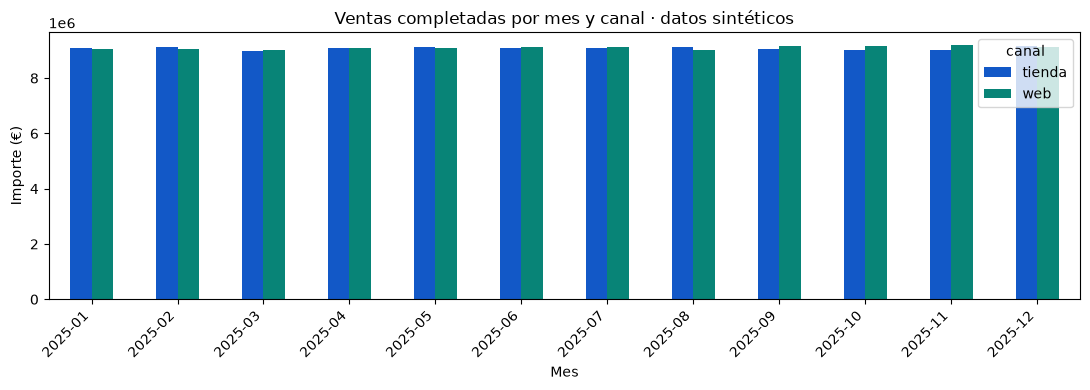

,operaciones,importe_euros
canal,,
tienda,267934,1.089381e+08
web,268536,1.091496e+08


In [16]:
grafico = informe.pivot(index='mes', columns='canal', values='importe_euros')
ax = grafico.plot(kind='bar', figsize=(11, 4), color=['#1258c7', '#088477'])
ax.set(title='Ventas completadas por mes y canal · datos sintéticos', xlabel='Mes', ylabel='Importe (€)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(SALIDA / 'ventas_por_mes.png', dpi=140)
plt.show()
display(informe.groupby('canal')[['operaciones', 'importe_euros']].sum())


## 8 · Entrega y retos
1. Filtra las ventas web de junio. Selecciona ID, SKU e importe. ¿Cuántas operaciones hay?
2. Agrega el importe por SKU y canal y ordena de mayor a menor.
3. Explica por qué el ticket medio global no es, en general, la media simple de los tickets de los grupos.
4. Introduce un archivo con una columna ausente en una copia de la entrada. ¿El proceso falla de forma visible?
5. Escribe dos observaciones descriptivas y una hipótesis que necesitaría nuevos datos. Distingue importe de beneficio y correlación de causalidad.

**Rúbrica (10 puntos):** extracción y trazabilidad (2), calidad y transformación (2), cuatro operaciones (2), automatización y comprobaciones (2), interpretación y límites (2).


In [17]:
# Soluciones orientativas a los retos 1–3. Intenta resolverlos primero.
junio_web = validos.loc[(validos['mes'].eq('2025-06')) & validos['canal'].eq('web') &
                        validos['estado'].eq('completado'), ['id', 'sku', 'importe_centimos']]
print('Operaciones web de junio:', len(junio_web))
ranking = completadas.groupby(['sku', 'canal'])['importe_centimos'].sum().sort_values(ascending=False)
display(ranking)
ticket_global = informe['importe_euros'].sum() / informe['operaciones'].sum()
print('Ticket global (€):', round(ticket_global, 2))
# La media simple da el mismo peso a grupos con distinto número de operaciones.


Operaciones web de junio: 22438


sku      canal 
SKU-303  web       3654393676
         tienda    3646427025
SKU-202  tienda    3638437769
         web       3632374963
SKU-101  web       3628190968
         tienda    3608940493
Name: importe_centimos, dtype: int64

Ticket global (€): 406.52


In [18]:
zip_resultados = shutil.make_archive(str(BASE / 'resultados_s03'), 'zip', SALIDA)
print('Resultados listos:', zip_resultados)
try:
    from google.colab import files
except ImportError:
    print('VS Code: abre laboratorio_s03/salida o el ZIP desde el explorador.')
else:
    files.download(zip_resultados)


Resultados listos: c:\Users\usuario\Desktop\CEU\Sistemas de big data\Entorno virtual\laboratorio_s03\resultados_s03.zip
VS Code: abre laboratorio_s03/salida o el ZIP desde el explorador.


## Escalabilidad y lecturas
Esta versión carga todo en memoria. El consumo puede ser varias veces el tamaño del CSV. Con más volumen: leer con `chunksize`, agregar sumas y recuentos por bloque y combinar resultados. No promediar medias de bloques sin ponderar; los duplicados entre bloques necesitan un control global. Parquet conserva tipos y suele comprimir mejor; una base de datos permite filtrar cerca del origen. Distribuir el cálculo solo cuando el problema lo justifique.

- [pandas: introducción y tutoriales](https://pandas.pydata.org/docs/getting_started/intro_tutorials/)
- [Conversión de fechas y errors=coerce](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.to_datetime.html)
- [Cuadernos en VS Code](https://code.visualstudio.com/docs/datascience/jupyter-notebooks)
- [Preguntas frecuentes de Colab](https://research.google.com/colaboratory/faq.html)
